In [1]:
# %%
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from PIL import Image, ImageDraw
from ipywidgets import interact, IntSlider, fixed
import os
import cv2

In [2]:
# %%
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint,seed):
    # Step 1: Generate Latin Hypercube Samples
    if seed is not None:
        np.random.seed(seed)
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # Step 2: Transform samples to satisfy the sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

# %%

In [8]:
seeds = [1,2,3,4,5]
arrays = []
n_samples = 96

for seed in seeds:
    df_lhs = pd.DataFrame(
        latin_hypercube_sum_constraint(
            n_samples=n_samples, n_variables=4, sum_constraint=270.0, seed=seed
        ),
        columns=["C", "M", "Y", "K"],
    )
    arrays.append(df_lhs.to_numpy().T)  

# display arrays
for i, array in enumerate(arrays):
    print(f"Results for seed {seeds[i]}:")
    print("C (blue) values:")
    print(", ".join(map(str, array[0])))
    print("\nM (red) values:")
    print(", ".join(map(str, array[1])))
    print("\nY (yellow) values:")
    print(", ".join(map(str, array[2])))
    print("\nK (black) values:")
    print(", ".join(map(str, array[3])))
    print("\n" + "-"*50 + "\n")


Results for seed 1:
C (blue) values:
72.50651484517367, 86.01843053990693, 87.90757760747523, 17.66339978828746, 73.76600918471335, 83.91066951076056, 110.0049951515841, 1.8247158477062702, 108.32652088782505, 7.224211950215921, 95.43253668361987, 37.201188421580405, 100.84843759138163, 54.02349604476224, 75.3490240364443, 80.46743284582737, 79.82034743565532, 90.09901819312707, 112.00435859746968, 48.15315294561697, 94.87766081426501, 94.87864997228323, 105.13147918436793, 18.346073185795934, 8.46852780597966, 61.36850575666919, 55.70719189688378, 63.24821262598964, 109.0998753486318, 115.81365156671262, 156.906922593074, 31.314450717488548, 132.6185284948286, 80.50347609891426, 56.64051076711207, 151.38469783269548, 79.63261388380278, 57.26989018657473, 42.6332439342261, 10.05368692204757, 113.05101597022419, 88.4227312450103, 73.14833195787779, 60.23544565391153, 8.512715412589388, 34.822868976457, 80.85748462075134, 52.92294111447308, 147.11259142426303, 53.010686313604644, 102.532

C:\Users\uwsun\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


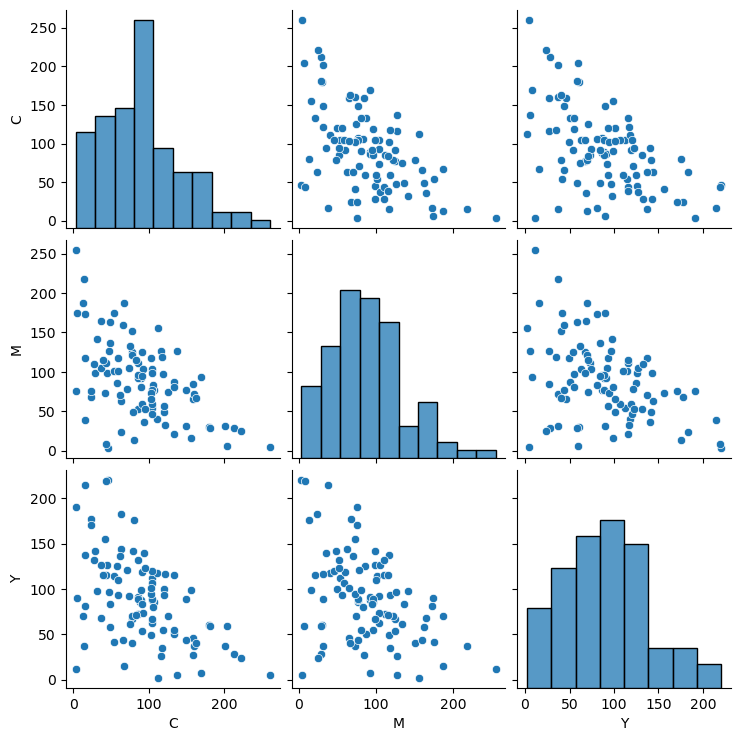

In [6]:
import seaborn as sns

sns.pairplot(df_lhs)
plt.show()

testing 4 samples

In [6]:
seeds = [1]
arrays = []
n_samples = 4

for seed in seeds:
    df_lhs = pd.DataFrame(
        latin_hypercube_sum_constraint(
            n_samples=n_samples, n_variables=4, sum_constraint=270.0, seed=seed
        ),
        columns=["C", "M", "Y", "K"],
    )
    arrays.append(df_lhs.to_numpy().T)  

# display arrays
for i, array in enumerate(arrays):
    print(f"Results for seed {seeds[i]}:")
    print("C (blue) values:")
    print(", ".join(map(str, array[0])))
    print("\nM (red) values:")
    print(", ".join(map(str, array[1])))
    print("\nY values:")
    print(", ".join(map(str, array[2])))
    print("\nK (black) values:")
    print(", ".join(map(str, array[3])))
    print("\n" + "-"*50 + "\n")

Results for seed 1:
C (blue) values:
71.05809443170705, 83.86700699218619, 4.506169411300044, 48.14905083668657

M (red) values:
55.912295139203444, 29.315613295486525, 151.3898373145717, 85.17266010030099

Y values:
56.95880807134397, 114.66529822858064, 89.51441943891615, 5.309367365920778

K (black) values:
86.07080235774558, 42.15208148374661, 24.58957383521207, 131.36892169709168

--------------------------------------------------

